In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
current_file = Path.cwd()
# print(current_file)
df = pd.read_csv(current_file / "Dataset" / "ushape.csv")


In [11]:
df.head()

,X,Y,CLASS
0,2.1200,-0.0462,1.0
1,0.8820,-0.0758,0.0
2,-0.0551,-0.0373,1.0
3,0.8300,-0.5390,1.0
4,2.1100,0.6620,1.0


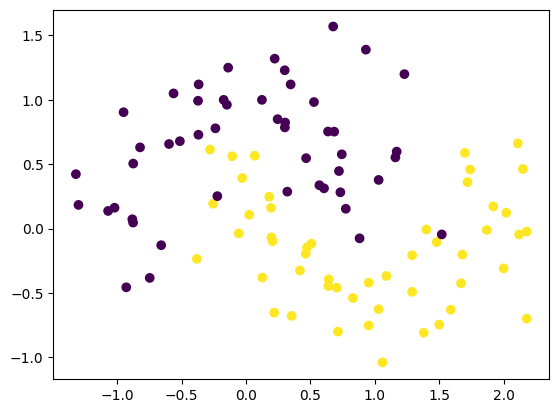

In [4]:
plt.scatter(df['X'],df['Y'],c=df['CLASS'])

In [5]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [24]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [25]:
model = Sequential()

model.add(Dense(10,activation='tanh',input_dim=2))
model.add(Dense(10,activation='tanh'))
model.add(Dense(10,activation='tanh'))
model.add(Dense(10,activation='tanh'))
model.add(Dense(1,activation='sigmoid')) 

# model.add(Dense(10,activation='relu',input_dim=2,kernel_initializer='he_normal'))
# model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
# model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
# model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
# model.add(Dense(1,activation='sigmoid'))

model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_5 (Dense)             (None, 10)                30        
                                                                 
 dense_6 (Dense)             (None, 10)                110       
                                                                 
 dense_7 (Dense)             (None, 10)                110       
                                                                 
 dense_8 (Dense)             (None, 10)                110       
                                                                 
 dense_9 (Dense)             (None, 1)                 11        
                                                                 
Total params: 371
Trainable params: 371
Non-trainable params: 0
_________________________________________________________________


In [26]:
model.get_weights()

[array([[ 0.05804461, -0.68744594, -0.16958153, -0.23590064, -0.5643805 ,
         -0.1913482 ,  0.00895399,  0.48294538, -0.09262884,  0.5744147 ],
        [-0.6078653 , -0.25601092, -0.6156813 , -0.18804693,  0.68920416,
         -0.07038105,  0.61343855, -0.29757562, -0.24569017, -0.29295954]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.26090753,  0.33696222,  0.37121773,  0.27238315, -0.00890368,
         -0.27958703,  0.16161114, -0.16172877, -0.28371397, -0.03433138],
        [ 0.027843  ,  0.33401215, -0.18020204,  0.16068149, -0.01919085,
         -0.07901326,  0.50237846,  0.35520005,  0.4129064 , -0.21653727],
        [-0.0878028 ,  0.23196995,  0.33326256, -0.25245777,  0.5181236 ,
          0.46436942, -0.16072795, -0.21180832,  0.3920365 , -0.20661473],
        [ 0.41476727,  0.20178169, -0.15939608,  0.51476157,  0.10323119,
         -0.21498564, -0.392607  , -0.4785428 , -0.10314277,  0.4004771 ],
        [ 0.05400

In [27]:
initial_weights = model.get_weights()

In [28]:
initial_weights[0] = np.random.randn(2,10)*np.sqrt(1/2)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[5] = np.zeros(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[7] = np.zeros(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(10,1)*np.sqrt(1/10)
initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [29]:
model.set_weights(initial_weights)

In [30]:
model.get_weights()

[array([[ 0.15395363, -0.57305616,  1.5257616 ,  0.3863937 ,  0.57357216,
          0.24882098,  0.5224731 ,  1.5339885 , -0.37583375,  0.9582748 ],
        [-0.45413634, -0.42826596, -1.4601644 , -0.8638951 ,  0.31841692,
         -0.235822  , -0.07421605, -0.38708675,  0.83362484, -0.50852644]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.3310079 ,  0.11321503, -0.5337481 ,  0.15572566,  0.26841766,
         -0.47144026, -0.20706342, -0.11021358, -0.41290018,  0.02035517],
        [ 0.06297465,  0.40511572, -0.12693594, -0.19034359,  0.06669079,
         -0.64227253,  0.05159337, -0.05524247, -0.6903998 , -0.5156689 ],
        [ 0.49524263,  0.36403656,  0.3061482 ,  0.02996536, -0.18335773,
          0.43650717, -0.08352514,  0.3243634 , -0.24944383, -0.4656982 ],
        [ 0.09982621,  0.30863082, -0.2359929 , -0.37357   , -0.26609626,
         -0.38263956,  0.17203732, -0.05906308,  0.17189492,  0.10102984],
        [ 0.13076

In [31]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [32]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 [==============================] - 0s 56ms/step - loss: 0.7690 - accuracy: 0.2278 - val_loss: 0.7766 - val_accuracy: 0.1500
Epoch 2/100
3/3 [==============================] - 0s 15ms/step - loss: 0.7563 - accuracy: 0.2278 - val_loss: 0.7613 - val_accuracy: 0.1500
Epoch 3/100
3/3 [==============================] - 0s 14ms/step - loss: 0.7450 - accuracy: 0.2152 - val_loss: 0.7466 - val_accuracy: 0.1500
Epoch 4/100
3/3 [==============================] - 0s 17ms/step - loss: 0.7339 - accuracy: 0.2278 - val_loss: 0.7324 - val_accuracy: 0.2000
Epoch 5/100
3/3 [==============================] - 0s 15ms/step - loss: 0.7237 - accuracy: 0.3165 - val_loss: 0.7187 - val_accuracy: 0.3000
Epoch 6/100
3/3 [==============================] - 0s 14ms/step - loss: 0.7137 - accuracy: 0.3418 - val_loss: 0.7055 - val_accuracy: 0.5000
Epoch 7/100
3/3 [==============================] - 0s 14ms/step - loss: 0.7046 - accuracy: 0.3418 - val_loss: 0.6930 - val_accuracy: 0.5500
Epoch 8/100
3/3 [===

In [33]:
model.get_weights()

[array([[ 0.2170646 , -0.70747226,  1.6688006 ,  0.36980823,  0.6946547 ,
          0.29917273,  0.4466323 ,  1.5272334 , -0.36585826,  0.8810712 ],
        [-0.59541374, -0.3517115 , -1.4271966 , -0.94267535,  0.16034041,
         -0.4125876 , -0.2492413 , -0.33162278,  0.9852709 , -0.6066773 ]],
       dtype=float32),
 array([-0.0068113 , -0.00087262, -0.21002354,  0.01079814, -0.17498867,
        -0.07405169, -0.02739321,  0.09415212,  0.01034842,  0.2045258 ],
       dtype=float32),
 array([[ 4.47658867e-01,  1.81557517e-02, -5.72653174e-01,
          3.88679951e-02,  2.13501826e-01, -5.64785123e-01,
         -3.63360614e-01, -3.07735115e-01, -2.35687435e-01,
          1.10901736e-01],
        [ 1.99653953e-01,  4.48227376e-01, -1.46239936e-01,
         -2.54872203e-01, -4.82250378e-02, -7.19476581e-01,
         -5.77934049e-02, -9.71490815e-02, -5.37650704e-01,
         -4.88219410e-01],
        [ 3.45973581e-01,  3.22472900e-01,  3.70423704e-01,
          2.67912857e-02, -1.22633

9600/9600 [==============================] - 9s 904us/step


<Axes: >

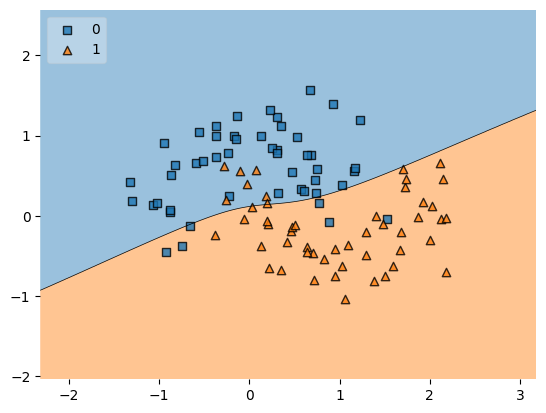

In [34]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X,y.astype('int'), clf=model, legend=2)

In [35]:
(np.random.randn(10,10)*0.01).min()

-0.027356046648505265

In [36]:
(np.random.randn(10,10)*0.01).max()

0.018223452974767625